# 04 · Ajuste de hiperparámetros de los 3 mejores candidatos

**Método: búsqueda aleatoria.** Es la misma lógica de `RandomizedSearchCV`: se muestrean configuraciones con `sklearn.model_selection.ParameterSampler`, sobre distribuciones continuas y en escala logarítmica donde corresponde. Cada configuración se evalúa con **la misma CV temporal** del notebook 03 (`evaluar_cv`).

**Por qué búsqueda aleatoria y no Optuna o una grilla:**
- Con 30 configuraciones por modelo, la búsqueda aleatoria cubre bien los hiperparámetros importantes sin el costo exponencial de una grilla. Para el presupuesto fijo del enunciado basta.
- No agrega dependencias (Optuna no está en el entorno del curso).
- Cada configuración es independiente y reproducible con la semilla.

**Por qué el bucle propio y no `RandomizedSearchCV.fit`:**
- La CV se **ajusta con datos submuestreados y valida a la prevalencia real**, y la AUC-PR de entrenamiento se **pondera** a esa misma prevalencia. `RandomizedSearchCV` calcularía la de entrenamiento sin ponderar, y la brecha no sería comparable con el notebook 03.
- Permite registrar **cada configuración como corrida hija** de MLflow, con las mismas métricas, mientras corre la búsqueda.

**Regla de mejora:** una mejora frente al modelo por defecto solo cuenta si **supera la desviación entre pliegues**.

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mlflow
from IPython.display import Image, display
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import ParameterSampler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

from datos import cargar_obt, metadatos_snapshot
from pipeline import SEMILLA, construir_modelo, dividir, CVTemporalSubmuestreada, evaluar_cv
from experimento import (configurar_mlflow, borrar_corridas, etiquetar, registrar_datos, registrar_resultado_cv,
                         entrenar_final, registrar_modelo, commit_git)
from resumen_tuning import resumir   # tabla + gráfico por modelo en docs/tuning/ al terminar cada uno

DOCS = Path.cwd().parent / "docs" / "tuning"
DOCS.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(DOCS / nombre, dpi=120); plt.close(fig)
    display(Image(filename=str(DOCS / nombre)))

print("MLflow:", configurar_mlflow(), "| commit:", commit_git())
print("corridas previas de tuning borradas:", borrar_corridas(["tuning"]))
df = cargar_obt()
X_ent, y_ent, X_pru, y_pru, ent, pru = dividir(df)
monto_ent = ent["amt"].to_numpy()
cv = CVTemporalSubmuestreada()
top3 = json.loads((Path.cwd().parent / "docs" / "modelos" / "top3_para_tuning.json").read_text(encoding="utf-8"))
pd.DataFrame(top3)

MLflow: http://127.0.0.1:5055 | commit: 4441e0a-con-cambios
corridas previas de tuning borradas: 0


,nombre,familia,cv_auc_pr_media,cv_auc_pr_std,run_id
0,hist_gradient_boosting,boosting,0.961244,0.016265,fb65308c5c97454c9567082b30206b3c
1,random_forest,bagging,0.940629,0.020175,7c39d1063bde43e295f5a48a99c9505e
2,mlp,red_neuronal,0.917724,0.023298,efc4fbf08527471ab0b4335e715728df


## 1. Espacios de búsqueda

Los rangos parten de los valores por defecto (que quedan dentro del rango). La escala se elige según cómo afecta cada hiperparámetro:

- **Escala logarítmica** (`loguniform`) para la tasa de aprendizaje y la regularización (`l2_regularization`, `alpha`, `C`). Su efecto es multiplicativo: pasar de 0,001 a 0,01 importa tanto como pasar de 0,01 a 0,1.
- **Enteros uniformes** (`randint`) para tamaños: árboles, hojas, iteraciones.
- **Listas** para opciones categóricas, como la arquitectura de la red, `max_features` o `class_weight`.

In [2]:
ESPACIOS = {
    "hist_gradient_boosting": {
        "learning_rate": loguniform(0.01, 0.3),          # defecto 0,1
        "max_iter": randint(100, 600),                   # defecto 100 (con early stopping automático: >10.000 filas)
        "max_leaf_nodes": randint(15, 128),              # defecto 31
        "min_samples_leaf": randint(10, 200),            # defecto 20
        "l2_regularization": loguniform(1e-4, 10),       # defecto 0
        "max_features": uniform(0.5, 0.5),               # fracción de columnas por división, 0,5-1,0 (defecto 1,0)
    },
    "random_forest": {
        "n_estimators": randint(100, 400),               # defecto 100
        "max_depth": [None, 8, 12, 16, 24],              # defecto None
        "min_samples_leaf": randint(1, 20),              # defecto 1
        "max_features": ["sqrt", "log2", 0.3, 0.5],      # defecto "sqrt"
        "class_weight": [None, "balanced_subsample"],    # defecto None
    },
    "mlp": {
        "hidden_layer_sizes": [(64,), (100,), (128,), (64, 32), (128, 64), (256, 128)],  # defecto (100,)
        "alpha": loguniform(1e-6, 1e-1),                 # defecto 1e-4 (regularización L2)
        "learning_rate_init": loguniform(1e-4, 1e-2),    # defecto 1e-3
        "batch_size": [128, 256, 512],                   # defecto min(200, n)
        "early_stopping": [True, False],                 # defecto False
    },
    "logistic_regression": {
        "C": loguniform(1e-3, 1e2),                      # defecto 1
        "class_weight": [None, "balanced"],
    },
    "extra": {},
}
BASE = {
    "hist_gradient_boosting": lambda **p: HistGradientBoostingClassifier(random_state=SEMILLA, **p),
    "random_forest": lambda **p: RandomForestClassifier(n_jobs=-1, random_state=SEMILLA, **p),
    "mlp": lambda **p: MLPClassifier(random_state=SEMILLA, **p),
    "logistic_regression": lambda **p: LogisticRegression(max_iter=1000, random_state=SEMILLA, **p),
}
N_CONFIG = 30
espacios_txt = {m: {k: (str(v.dist.name) + str(v.args) if hasattr(v, "dist") else str(v)) for k, v in ESPACIOS[m].items()} for m in ESPACIOS}
(DOCS / "espacios_de_busqueda.json").write_text(json.dumps({t["nombre"]: espacios_txt[t["nombre"]] for t in top3}, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({t["nombre"]: espacios_txt[t["nombre"]] for t in top3}, indent=2, ensure_ascii=False))

{
  "hist_gradient_boosting": {
    "learning_rate": "loguniform(0.01, 0.3)",
    "max_iter": "randint(100, 600)",
    "max_leaf_nodes": "randint(15, 128)",
    "min_samples_leaf": "randint(10, 200)",
    "l2_regularization": "loguniform(0.0001, 10)",
    "max_features": "uniform(0.5, 0.5)"
  },
  "random_forest": {
    "n_estimators": "randint(100, 400)",
    "max_depth": "[None, 8, 12, 16, 24]",
    "min_samples_leaf": "randint(1, 20)",
    "max_features": "['sqrt', 'log2', 0.3, 0.5]",
    "class_weight": "[None, 'balanced_subsample']"
  },
  "mlp": {
    "hidden_layer_sizes": "[(64,), (100,), (128,), (64, 32), (128, 64), (256, 128)]",
    "alpha": "loguniform(1e-06, 0.1)",
    "learning_rate_init": "loguniform(0.0001, 0.01)",
    "batch_size": "[128, 256, 512]",
    "early_stopping": "[True, False]"
  }
}


## 2. Búsqueda: una corrida padre por modelo y 30 corridas hijas

- **Cada corrida hija** (`fase=tuning`) registra los hiperparámetros, la semilla, los datos (tabla, fecha de corte, hash), la AUC-PR de entrenamiento, la media y la desviación de la CV, la AUC-PR por pliegue y los segundos.
- **La corrida padre** registra el espacio de búsqueda, la mejor configuración, la mejora frente al modelo por defecto y el **pipeline entrenado de la mejor configuración** (con firma y ejemplo de entrada).

No se guarda un modelo por cada configuración: serían 90 modelos (los de RandomForest pesan decenas de MB cada uno) para configuraciones que no se usan.

In [3]:
resumen, todas = [], []
for t in top3:
    nombre = t["nombre"]
    configs = list(ParameterSampler(ESPACIOS[nombre], n_iter=N_CONFIG, random_state=SEMILLA))
    t0_modelo = time.perf_counter()
    with mlflow.start_run(run_name=f"tuning_{nombre}") as padre:
        etiquetar("tuning", t["familia"], rol="padre", modelo=nombre)
        registrar_datos()
        mlflow.log_params({"busqueda": "aleatoria (ParameterSampler)", "n_configuraciones": N_CONFIG,
                           "modelo_base_run_id": t["run_id"]})
        mlflow.log_dict(espacios_txt[nombre], "espacio_de_busqueda.json")
        filas = []
        for k, p in enumerate(configs):
            p = {c: (int(v) if isinstance(v, (np.integer,)) else v) for c, v in p.items()}
            with mlflow.start_run(run_name=f"{nombre}_cfg{k:02d}", nested=True) as hija:
                etiquetar("tuning", t["familia"], rol="hija", modelo=nombre, configuracion=str(k))
                registrar_datos()
                mlflow.log_params({f"modelo__{c}": str(v) for c, v in p.items()})
                res = evaluar_cv(construir_modelo(BASE[nombre](**p)), X_ent, y_ent, cv, monto=monto_ent)
                registrar_resultado_cv(res)
                filas.append({"modelo": nombre, "configuracion": k, **{c: str(v) for c, v in p.items()},
                              "auc_pr_entrenamiento": res["entrenamiento_auc_pr_media"], "cv_auc_pr_media": res["cv_auc_pr_media"],
                              "cv_auc_pr_std": res["cv_auc_pr_std"], "brecha_auc_pr": res["brecha_auc_pr"],
                              "segundos_entrenamiento": res["segundos_entrenamiento"], "cv_perdida_neta_oof": res["cv_perdida_neta_oof"],
                              "run_id": hija.info.run_id, "params_obj": p})
            print(f"{nombre} cfg{k:02d}: AUC-PR CV {res['cv_auc_pr_media']:.4f} ± {res['cv_auc_pr_std']:.4f} ({res['segundos_entrenamiento']:.0f} s)")
        r = pd.DataFrame(filas).sort_values("cv_auc_pr_media", ascending=False)
        mejor = r.iloc[0]
        mejora = mejor["cv_auc_pr_media"] - t["cv_auc_pr_media"]
        ruido = max(mejor["cv_auc_pr_std"], t["cv_auc_pr_std"])
        final, met = entrenar_final(construir_modelo(BASE[nombre](**mejor["params_obj"])), X_ent, y_ent)
        mlflow.log_params({f"mejor__{c}": str(v) for c, v in mejor["params_obj"].items()})
        mlflow.log_metrics({"cv_auc_pr_media": mejor["cv_auc_pr_media"], "cv_auc_pr_std": mejor["cv_auc_pr_std"],
                            "auc_pr_entrenamiento": mejor["auc_pr_entrenamiento"], "brecha_auc_pr": mejor["brecha_auc_pr"],
                            "segundos_entrenamiento": mejor["segundos_entrenamiento"], "cv_perdida_neta_oof": mejor["cv_perdida_neta_oof"],
                            "default_cv_auc_pr_media": t["cv_auc_pr_media"], "default_cv_auc_pr_std": t["cv_auc_pr_std"],
                            "mejora_vs_default": mejora, "mejora_supera_desviacion": float(mejora > ruido),
                            "segundos_busqueda_total": time.perf_counter() - t0_modelo, **met})
        mlflow.set_tag("mejor_configuracion_run_id", mejor["run_id"])
        registrar_modelo(final, X_ent)
        resumen.append({"modelo": nombre, "familia": t["familia"], "default_cv_auc_pr": t["cv_auc_pr_media"], "default_cv_std": t["cv_auc_pr_std"],
                        "tuned_cv_auc_pr": mejor["cv_auc_pr_media"], "tuned_cv_std": mejor["cv_auc_pr_std"],
                        "tuned_auc_pr_entrenamiento": mejor["auc_pr_entrenamiento"], "tuned_brecha": mejor["brecha_auc_pr"],
                        "mejora": mejora, "desviacion_de_referencia": ruido, "mejora_cuenta": bool(mejora > ruido),
                        "tuned_perdida_neta_oof": mejor["cv_perdida_neta_oof"], "mejores_params": json.dumps({c: str(v) for c, v in mejor["params_obj"].items()}),
                        "minutos_busqueda": (time.perf_counter() - t0_modelo) / 60, "run_id_padre": padre.info.run_id,
                        "run_id_mejor_hija": mejor["run_id"]})
        todas.append(r.drop(columns="params_obj"))
    print(f"==> {nombre}: mejor {mejor['cv_auc_pr_media']:.4f} vs defecto {t['cv_auc_pr_media']:.4f} (mejora {mejora:+.4f}, desv. {ruido:.4f}) en {(time.perf_counter()-t0_modelo)/60:.1f} min")
    print("    tabla y gráfico guardados en docs/tuning/ para:", resumir())

2026/11/18 23:56:42 INFO mlflow.tracking._tracking_service.client: 🏃 View run hist_gradient_boosting_cfg00 at: http://127.0.0.1:5055/#/experiments/1/runs/0ae155a6febc4a5898e2604cf79dae06.


2026/11/18 23:56:42 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


hist_gradient_boosting cfg00: AUC-PR CV 0.9594 ± 0.0193 (4 s)


2026/11/18 23:58:11 INFO mlflow.tracking._tracking_service.client: 🏃 View run hist_gradient_boosting_cfg01 at: http://127.0.0.1:5055/#/experiments/1/runs/837028b3aa58448abfb9173eb70a5439.


2026/11/18 23:58:11 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


hist_gradient_boosting cfg01: AUC-PR CV 0.9533 ± 0.0177 (32 s)


... (272 outputs left out)

2026/11/19 00:52:25 INFO mlflow.tracking._tracking_service.client: 🏃 View run tuning_mlp at: http://127.0.0.1:5055/#/experiments/1/runs/0c5a2d2b4db64a3996f8806d90066bc7.


2026/11/19 00:52:25 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://127.0.0.1:5055/#/experiments/1.


==> mlp: mejor 0.9284 vs defecto 0.9177 (mejora +0.0107, desv. 0.0255) en 21.6 min


    tabla y gráfico guardados en docs/tuning/ para: ['mlp', 'random_forest', 'hist_gradient_boosting']


## 3. Resultados del tuning

In [4]:
res_tuning = pd.DataFrame(resumen)
res_tuning.to_csv(DOCS / "resumen_tuning.csv", index=False)
todas_df = pd.concat(todas)
todas_df.to_csv(DOCS / "todas_las_configuraciones.csv", index=False)
print("Corridas hijas registradas:", len(todas_df))
res_tuning.drop(columns=["run_id_padre", "run_id_mejor_hija"]).round(4)

Corridas hijas registradas: 90


,modelo,familia,default_cv_auc_pr,default_cv_std,tuned_cv_auc_pr,tuned_cv_std,tuned_auc_pr_entrenamiento,tuned_brecha,mejora,desviacion_de_referencia,mejora_cuenta,tuned_perdida_neta_oof,mejores_params,minutos_busqueda
0,hist_gradient_boosting,boosting,0.9612,0.0163,0.9637,0.0151,0.9983,0.0346,0.0025,0.0163,False,34450.93,"{""l2_regularization"": ""1.194832816854544"", ""le...",18.8952
1,random_forest,bagging,0.9406,0.0202,0.9394,0.0189,0.9851,0.0457,-0.0013,0.0202,False,43289.54,"{""class_weight"": ""None"", ""max_depth"": ""None"", ...",15.4210
2,mlp,red_neuronal,0.9177,0.0233,0.9284,0.0255,0.9833,0.0549,0.0107,0.0255,False,66788.03,"{""alpha"": ""0.02525452445242111"", ""batch_size"":...",21.6237


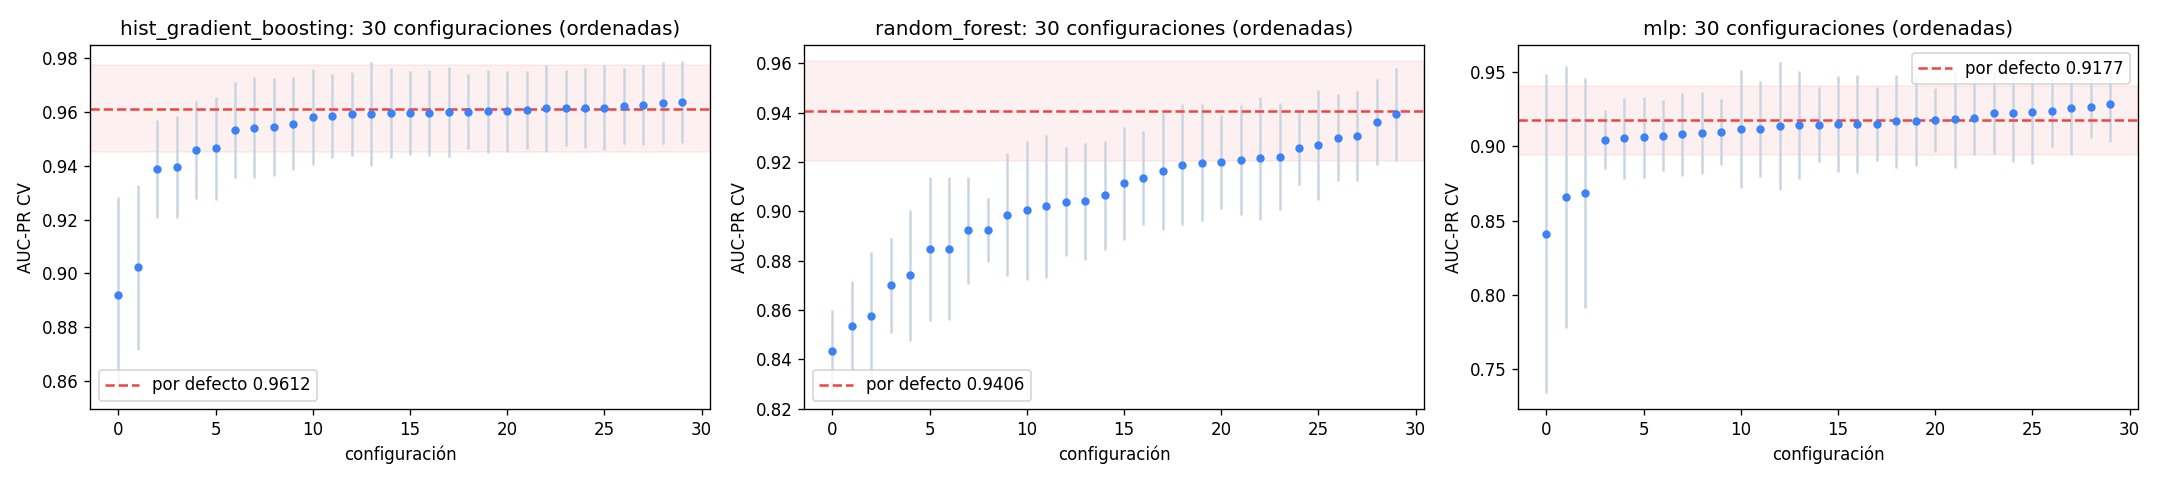

In [5]:
fig, axes = plt.subplots(1, len(todas), figsize=(6 * len(todas), 4))
for ax, r, t in zip(np.atleast_1d(axes), todas, top3):
    r = r.sort_values("cv_auc_pr_media").reset_index(drop=True)
    ax.errorbar(range(len(r)), r["cv_auc_pr_media"], yerr=r["cv_auc_pr_std"], fmt="o", ms=4, color="#3b82f6", ecolor="#cbd5e1")
    ax.axhline(t["cv_auc_pr_media"], color="#ef4444", ls="--", label=f"por defecto {t['cv_auc_pr_media']:.4f}")
    ax.axhspan(t["cv_auc_pr_media"] - t["cv_auc_pr_std"], t["cv_auc_pr_media"] + t["cv_auc_pr_std"], color="#ef4444", alpha=.08)
    ax.set_title(f"{t['nombre']}: 30 configuraciones (ordenadas)"); ax.set_xlabel("configuración"); ax.set_ylabel("AUC-PR CV"); ax.legend()
guardar(fig, "tuning_configuraciones.png")

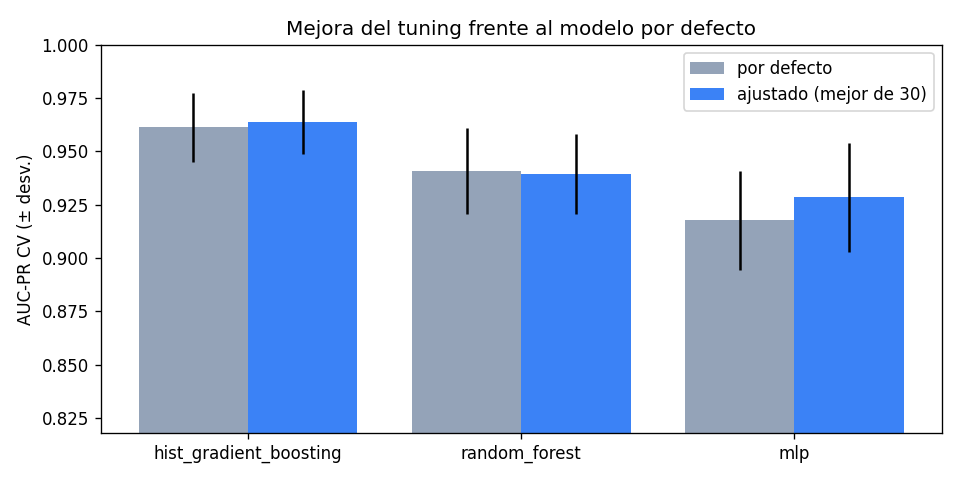

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(res_tuning))
ax.bar(x - .2, res_tuning["default_cv_auc_pr"], .4, yerr=res_tuning["default_cv_std"], label="por defecto", color="#94a3b8")
ax.bar(x + .2, res_tuning["tuned_cv_auc_pr"], .4, yerr=res_tuning["tuned_cv_std"], label="ajustado (mejor de 30)", color="#3b82f6")
ax.set_xticks(x, res_tuning["modelo"]); ax.set_ylim(max(0, res_tuning[["default_cv_auc_pr", "tuned_cv_auc_pr"]].min().min() - .1), 1)
ax.set_ylabel("AUC-PR CV (± desv.)"); ax.set_title("Mejora del tuning frente al modelo por defecto"); ax.legend()
guardar(fig, "tuning_mejora.png")

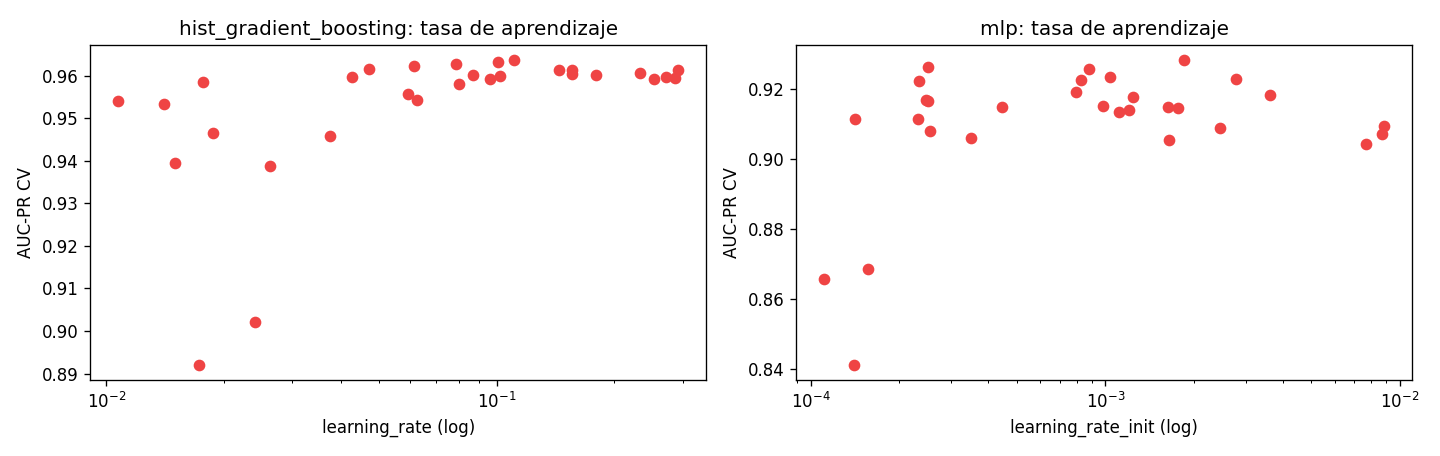

In [7]:
# Efecto de la tasa de aprendizaje (escala log) donde aplica
lr_cols = {"hist_gradient_boosting": "learning_rate", "mlp": "learning_rate_init"}
con_lr = [(r, lr_cols[t["nombre"]], t["nombre"]) for r, t in zip(todas, top3) if t["nombre"] in lr_cols]
if con_lr:
    fig, axes = plt.subplots(1, len(con_lr), figsize=(6 * len(con_lr), 3.8))
    for ax, (r, col, nombre) in zip(np.atleast_1d(axes), con_lr):
        ax.scatter(r[col].astype(float), r["cv_auc_pr_media"], color="#ef4444")
        ax.set_xscale("log"); ax.set_xlabel(col + " (log)"); ax.set_ylabel("AUC-PR CV"); ax.set_title(f"{nombre}: tasa de aprendizaje")
    guardar(fig, "tuning_tasa_aprendizaje.png")

**Lectura:** la columna `mejora_cuenta` aplica la regla del enunciado: la mejora tiene que superar la desviación entre pliegues, ya sea la del modelo por defecto o la del ajustado, la que sea mayor. Si no la supera, el modelo ajustado **no se considera mejor** que el de por defecto, aunque su media sea más alta. Los dos mejores modelos ajustados pasan al notebook 05.

In [8]:
mejores = res_tuning.sort_values("tuned_cv_auc_pr", ascending=False)
(DOCS / "mejores_para_seleccion.json").write_text(mejores.to_json(orient="records", indent=2, force_ascii=False), encoding="utf-8")
mejores[["modelo", "tuned_cv_auc_pr", "tuned_cv_std", "mejora", "mejora_cuenta", "run_id_padre"]]

,modelo,tuned_cv_auc_pr,tuned_cv_std,mejora,mejora_cuenta,run_id_padre
0,hist_gradient_boosting,0.963704,0.015132,0.002460,False,af38ded7de894c8ca3e600a9c1ad03eb
1,random_forest,0.939359,0.018940,-0.001270,False,54a38a3975784db4bc9de3669ac509d8
2,mlp,0.928421,0.025519,0.010697,False,0c5a2d2b4db64a3996f8806d90066bc7
